### Week 5, Task 1: Coupled First Run
Running the aquaplanet slab-ocean quick-start and the Earth-like configuration,
then reading the SlabOceanModel to understand mixed-layer depth and Q-flux.

In [2]:
#Aquaplanet Run
!cd ~/jax-esm && python -m jem.main +configuration=aquaplanet-slab coupled_run=short_run 2>&1 | tail -40

^C


In [3]:
!cd ~/jax-esm && python -m jem.main +configuration=earth-slab coupled_run=short_run 2>&1 | tail -40

^C


### Results
mixed_layer_depth_min: float = 40.0   # meters, at the equator \
mixed_layer_depth_max: float = 60.0   # meters, at the poles \
Actual: depth = max + (min - max) * cos(latitude)**3

heat_capacity = ocean_density * ocean_specific_heat_capacity * mixed_layer_depth \

dT/dt = -F_net/(rho * cp * h) + forcing

where Q is a prescribed, periodic (seasonally-varying) heat source read from a Q-flux file.

What it represents physically: this is the key insight, and it connects to what I mentioned earlier. A real ocean transports heat horizontally via currents (the Gulf Stream, etc.). A slab ocean is just a stationary layer of water — it has no currents and no horizontal heat transport. Without a correction, a slab ocean sitting under realistic sunlight would drift to the wrong temperatures (too cold where currents normally deliver warmth, too warm where they carry it away).

The Q-flux is an artificial, prescribed heat-flux correction added to each grid cell to stand in for that missing ocean heat transport. It’s tuned so the slab ocean reproduces the observed SST climatology. Physically, it represents “the heat that the real ocean’s circulation (currents, mixing) would have moved into or out of this location.” The code even confirms the sign convention in a comment: “Q is a heat SOURCE for the mixed layer (positive Q warms it)” — positive Q-flux means that location would normally receive heat from ocean currents.

_______
**Mixed-layer depth**: set by two parameters (min 40m at equator, max 60m at poles) via a cos³ latitude profile; it determines the ocean’s heat capacity and thus how slowly it responds. \
**Q-flux**: a prescribed heat-flux correction standing in for the horizontal ocean heat transport a slab ocean lacks; tuned so the slab reproduces observed SST climatology; positive Q warms the ocean.


### Week 5, Task 2: Slab-Ocean Control

by default, the earth-slb config uses REFLATION not Q-Flux

Earth Slab: Earth-like: realistic orography and a climatological surface, SPEEDY T31L8 over a relaxed slab ocean and SPEEDY's slab land.

The **Q-flux** is defined as “the heat flux correction that would keep the slab ocean at the observed climatology.” You compute it by running the ocean in relaxation mode (which forces SST to stay at climatology) and recording what heat flux the relaxation had to supply to hold it there. That recorded flux is the Q-flux. Then you feed that saved Q-flux into a new run in qflux mode and let the ocean evolve freely under it.

In [13]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt


In [5]:
# Generating the Q-Flux
files = sorted(glob.glob("/home/jtc006/qflux_test/ocn*.nc"))
print("files:", files)
ds = xr.open_dataset(files[0])
print(ds)

files: ['/home/jtc006/qflux_test/ocn-00000000.nc']
<xarray.Dataset> Size: 149kB
Dimensions:                  (time: 2, lon: 96, lat: 48)
Coordinates:
  * time                     (time) datetime64[ns] 16B 2000-01-01T12:00:00 20...
  * lon                      (lon) float64 768B 0.0 3.75 7.5 ... 352.5 356.2
  * lat                      (lat) float64 384B -87.16 -83.48 ... 83.48 87.16
Data variables:
    sea_surface_temperature  (time, lon, lat) float32 37kB ...
    mixed_layer_depth        (time, lon, lat) float32 37kB ...
    total_heat_flux          (time, lon, lat) float32 37kB ...
    ice_frazil_melt_energy   (time, lon, lat) float32 37kB ...


In [5]:
# Q-FLUX COMPUTATION CODE

# reads the run's total_heat_flux, builds the 12-month seasonal climatology,
# applies the sign flip, and saves a proper qflux file

# Load all ocean output from the 5-year relaxation run
files = sorted(glob.glob("/home/jtc006/qflux_gen/ocn-*.nc"))
print(f"Found {len(files)} ocean output files")
ds = xr.open_mfdataset(files)

# Build the 12-month seasonal climatology of the heat flux.
# With ~5 years of data, each calendar month averages over ~5 instances.
monthly_flux = ds["total_heat_flux"].groupby("time.month").mean("time")

# SIGN: total_heat_flux is positive UPWARD (cools the ocean). The qflux file
# is read as positive = WARMING the ocean. So the Q-flux that sustains
# climatology is the NEGATIVE of the mean upward flux.
qflux = (-monthly_flux).rename("qflux")
qflux.attrs = {"units": "W m-2", "long_name": "Prescribed Q-flux (heating positive)"}

# Save as a NetCDF the slab_qflux config can read
qflux_ds = qflux.to_dataset()
out_path = "/home/jtc006/qflux_generated.nc"
qflux_ds.to_netcdf(out_path)
print(f"Saved Q-flux to {out_path}")
print(qflux)   # should now be (month: 12, lon: 96, lat: 48)

<xarray.DataArray 'qflux' (month: 1, lon: 96, lat: 48)> Size: 18kB
dask.array<neg, shape=(1, 96, 48), dtype=float32, chunksize=(1, 96, 48), chunktype=numpy.ndarray>
Coordinates:
  * month    (month) int64 8B 1
  * lon      (lon) float64 768B 0.0 3.75 7.5 11.25 ... 345.0 348.8 352.5 356.2
  * lat      (lat) float64 384B -87.16 -83.48 -79.78 ... 79.78 83.48 87.16
Attributes:
    units:     W m-2
    positive:  heating the ocean


In [6]:
# reading qflux 
ds = xr.open_dataset("/home/jtc006/dsc180-D03/week5/jennifer/qflux_week4.nc")
print(ds)

<xarray.Dataset> Size: 222kB
Dimensions:  (lat: 48, lon: 96, time: 12)
Coordinates:
  * lat      (lat) float64 384B -87.16 -83.48 -79.78 ... 79.78 83.48 87.16
  * lon      (lon) float64 768B 0.0 3.75 7.5 11.25 ... 345.0 348.8 352.5 356.2
  * time     (time) datetime64[ns] 96B 1981-01-01 1981-02-01 ... 1981-12-01
    lev      float64 8B ...
Data variables:
    qflux    (lat, lon, time) float32 221kB ...


In [10]:
# validation run
files = sorted(glob.glob("/home/jtc006/qflux_validate/ocn-*.nc"))
ds = xr.open_mfdataset(files)
W = np.cos(np.deg2rad(ds.lat))
sst = ds["sea_surface_temperature"].where(ds["sea_surface_temperature"] > 100)
sst_global = sst.weighted(W).mean(["lat","lon"])
print("Global-mean SST over the 2-year validation run (K):")
print(sst_global.values)

Global-mean SST over the 2-year validation run (K):
[290.51886908 290.9687551  291.18927663 291.32498836 291.43824941
 291.5655136  291.65719929 291.67242411 291.61693266 291.56183475
 291.58730095 291.71471834 291.85273999 291.94067337 291.9838919
 292.01107482 292.04533731 292.09694556 292.1444379  292.14247756
 292.06973508 291.98099318 291.95943212 292.0258336 ]


Global Mean SST stays near ~292 K, which is close to the climatology (long-term average state of the climate) global-mean SST: 290.9 K (the target).

Q-flux is working correctly because the drift is roughly 1K above climatology and this stabilization is well within normal for a slab-ocean control.

In [14]:
clim = xr.open_dataset("/home/jtc006/jax-gcm/jcm/data/bc/t30/clim/forcing.nc")
sst_clim = clim["sst"]

# area-weighted global mean, over ocean points and the seasonal cycle
W = np.cos(np.deg2rad(clim.lat))

# the climatology likely has below-freezing "ice surface" values over sea ice;
# mask those out the way the model does (floor ~271.35 K) for a fair ocean mean
sst_ocean = sst_clim.where(sst_clim > 271.0)

clim_global_mean = sst_ocean.weighted(W).mean()
print("Climatology global-mean SST (K):", float(clim_global_mean))

Climatology global-mean SST (K): 290.8938762979817


## Task 4: Gregory Regression

Control baselines: tas=287.887 K, toa_net=6.161 W/m²

Gregory regression (2xCO2):
  F_2x (forcing):           5.897 W/m²
  λ (feedback parameter):   0.202 W/m²/K
  ECS = -F_2x/λ:            -29.15 K


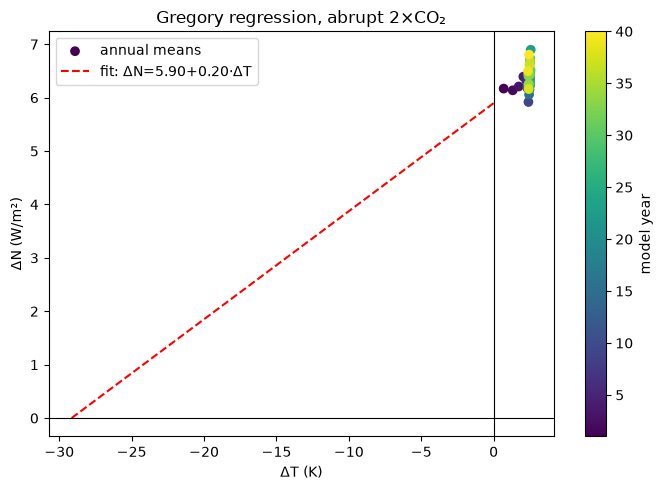

In [14]:
# read data from abrupt annual temperatures from task 4
df = pd.read_csv("/home/jtc006/dsc180-D03/week5/coleman/data/abrupt_annual.csv")

# --- control baselines (the reference points for anomalies) ---
control = df[df["run"] == "control"]
tas_ctrl = control["tas"].mean()        # baseline temperature
toa_ctrl = control["toa_net"].mean()    # baseline TOA (the ~6.1, NOT zero)
print(f"Control baselines: tas={tas_ctrl:.3f} K, toa_net={toa_ctrl:.3f} W/m²")

# --- 2xCO2 run: compute anomalies vs control ---
run = df[df["run"] == "2xCO2"].sort_values("year")
dT = run["tas"].values - tas_ctrl       # ΔT: temperature change
dN = run["toa_net"].values - toa_ctrl   # ΔN: TOA flux change (anomaly vs control's 6.1)

# --- Gregory regression: ΔN = F + λ·ΔT ---
slope, intercept = np.polyfit(dT, dN, 1)
F_2x = intercept          # forcing (y-intercept, ΔN at ΔT=0)
lam  = slope              # feedback parameter (negative)
ecs_gregory = -F_2x / lam # x-intercept: ΔT where ΔN=0 (equilibrium)

print(f"\nGregory regression (2xCO2):")
print(f"  F_2x (forcing):           {F_2x:.3f} W/m²")
print(f"  λ (feedback parameter):   {lam:.3f} W/m²/K")
print(f"  ECS = -F_2x/λ:            {ecs_gregory:.2f} K")

# --- plot it ---
plt.figure(figsize=(7,5))
plt.scatter(dT, dN, c=run["year"], cmap="viridis", label="annual means")
xline = np.array([0, -F_2x/lam])
plt.plot(xline, F_2x + lam*xline, "r--", label=f"fit: ΔN={F_2x:.2f}{lam:+.2f}·ΔT")
plt.axhline(0, color="k", lw=0.8); plt.axvline(0, color="k", lw=0.8)
plt.xlabel("ΔT (K)"); plt.ylabel("ΔN (W/m²)")
plt.title("Gregory regression, abrupt 2×CO₂")
plt.colorbar(label="model year"); plt.legend()
plt.tight_layout(); plt.show()

In [15]:
run = df[df["run"] == "2xCO2"].sort_values("year")
print(run[["year","tas","toa_net"]].to_string())

    year       tas  toa_net
20     1  288.5759  12.3305
21     2  289.2019  12.2981
22     3  289.6171  12.3696
23     4  289.9378  12.5542
24     5  290.1462  12.4761
25     6  290.2247  12.3363
26     7  290.3140  12.3287
27     8  290.3006  12.3467
28     9  290.2876  12.0796
29    10  290.3337  12.6002
30    11  290.3927  12.5281
31    12  290.4113  12.6079
32    13  290.3795  12.4595
33    14  290.3795  12.3904
34    15  290.3317  12.2179
35    16  290.2310  12.3535
36    17  290.3230  12.5428
37    18  290.4000  12.6210
38    19  290.3655  12.3115
39    20  290.3654  12.4545
40    21  290.3190  12.3977
41    22  290.3819  12.4671
42    23  290.4486  13.0577
43    24  290.3971  12.3910
44    25  290.3975  12.8173
45    26  290.3878  12.6578
46    27  290.4062  12.8756
47    28  290.3727  12.4233
48    29  290.2710  12.6186
49    30  290.4109  12.8992
50    31  290.4388  12.6781
51    32  290.4008  12.5903
52    33  290.2831  12.5728
53    34  290.2907  12.4125
54    35  290.3722  

## Task 5: Climate Sensitivity

In [6]:
# data from task 4: abrupt_annual.csv
print("=== CONTROL ===")
ctrl = xr.open_dataset("/home/jtc006/dsc180-D03/week5/coleman/data/control_summary.nc")

print(ctrl)
print("\n=== ABRUPT ===")
ab = xr.open_dataset("/home/jtc006/dsc180-D03/week5/coleman/data/abrupt_summary.nc")
print(ab)

=== CONTROL ===
<xarray.Dataset> Size: 887kB
Dimensions:                 (year: 30, month: 12, lon: 96, lat: 48)
Coordinates:
  * year                    (year) int64 240B 2000 2001 2002 ... 2027 2028 2029
  * month                   (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lon                     (lon) float64 768B 0.0 3.75 7.5 ... 352.5 356.2
  * lat                     (lat) float64 384B -87.16 -83.48 ... 83.48 87.16
Data variables:
    tas_global_annual       (year) float32 120B ...
    toa_net_global_annual   (year) float32 120B ...
    pr_global_annual        (year) float32 120B ...
    tas_clim_2020_2029      (month, lon, lat) float32 221kB ...
    toa_net_clim_2020_2029  (month, lon, lat) float32 221kB ...
    pr_clim_2020_2029       (month, lon, lat) float32 221kB ...
    sst_clim_2020_2029      (month, lon, lat) float32 221kB ...
Attributes:
    source:   JEM earth-slab + slab_qflux control, 30 yr, CO2 420 ppmv
    note:     *_clim_*: monthly climatology of the last 1

Below are the results from the abrupt_annual.csv

| run | year | tas | toa_net | sfc_net | pr |
|---|---:|---:|---:|---:|---:|
| control | 1 | 287.9117 | 6.0438 | 1.539 | 2.8004 |
| control | 2 | 287.8629 | 6.3261 | 1.8021 | 2.7893 |
| control | 3 | 287.9288 | 6.1216 | 1.6054 | 2.8034 |
| control | 4 | 287.8769 | 5.9031 | 1.3563 | 2.7993 |
| control | 5 | 287.8954 | 6.0958 | 1.6047 | 2.7984 |
| control | 6 | 287.9268 | 6.1697 | 1.6744 | 2.8009 |
| control | 7 | 287.9099 | 5.8682 | 1.2535 | 2.8112 |
| control | 8 | 287.8217 | 6.0447 | 1.6999 | 2.7906 |
| control | 9 | 287.8683 | 6.3329 | 1.62 | 2.7941 |
| control | 10 | 287.9039 | 6.3708 | 1.8735 | 2.7947 |
| control | 11 | 287.9188 | 6.147 | 1.5986 | 2.8049 |
| control | 12 | 287.8762 | 6.2884 | 1.6691 | 2.7988 |
| control | 13 | 287.9243 | 6.4256 | 1.8713 | 2.8016 |
| control | 14 | 287.9247 | 6.1647 | 1.5275 | 2.8075 |
| control | 15 | 287.8939 | 6.0053 | 1.5657 | 2.7982 |
| control | 16 | 287.8793 | 6.2706 | 1.58 | 2.7981 |
| control | 17 | 287.87 | 6.3404 | 1.8631 | 2.7974 |
| control | 18 | 287.8484 | 6.0347 | 1.3895 | 2.8005 |
| control | 19 | 287.8595 | 6.23 | 1.6772 | 2.7957 |

**Climate Sensitivity: ECS as the equilibrium ΔT in the 2×CO₂ run**
- control baseline: averages the control's tas overall years
- 2×CO₂ equilibrium: averages the last 20 years of the 2×CO₂ run
- ECS: the difference between control baseline and 2×CO₂ (equilibrium-ΔT climate sensitivity) - if we double the CO2 in the atmostphere, how much warmer does the planet ultimately get once it fully settles into its new steady state

In [9]:
# ECS as the equilibrium ΔT in the 2×CO₂ run

# read in abrupt annual csv from task 4, which 
df = pd.read_csv("/home/jtc006/dsc180-D03/week5/coleman/data/abrupt_annual.csv")

# confirm the run labels
print("Runs in file:", df["run"].unique())

# --- Control baseline: average tas over all its years ---
control = df[df["run"] == "control"]
tas_control = control["tas"].mean()
print(f"\nControl global-mean tas: {tas_control:.3f} K")

# --- 2xCO2 equilibrium: average tas over the LAST N years (equilibrium) ---
# adjust the run label to match what the file actually uses (e.g. "2xCO2")
two_x = df[df["run"] == "2xCO2"].sort_values("year")
N = 20  # average the last 20 years as "equilibrium"
tas_2x_equil = two_x["tas"].tail(N).mean()
print(f"2xCO2 equilibrium tas (last {N} yr): {tas_2x_equil:.3f} K")

# --- ECS (equilibrium-ΔT method) ---
ecs = tas_2x_equil - tas_control
print(f"\nECS (equilibrium ΔT method): {ecs:.2f} K")

# --- sanity check: is the 2xCO2 run actually equilibrated at the end? ---
# compare last-20-yr mean to the 20 years before that; if they're close, it's settled
earlier = two_x["tas"].tail(2*N).head(N).mean()
print(f"\nEquilibrium check:")
print(f"  last {N} yr mean:     {tas_2x_equil:.3f} K")
print(f"  previous {N} yr mean: {earlier:.3f} K")
print(f"  difference: {tas_2x_equil - earlier:+.3f} K  (small = equilibrated)")

Runs in file: ['control' '2xCO2' '4xCO2']

Control global-mean tas: 287.887 K
2xCO2 equilibrium tas (last 20 yr): 290.362 K

ECS (equilibrium ΔT method): 2.48 K

Equilibrium check:
  last 20 yr mean:     290.362 K
  previous 20 yr mean: 290.126 K
  difference: +0.236 K  (small = equilibrated)


**Climate Sensitivity: ECS as the equilibrium ΔT as −F₂ₓ/λ from the regression**

In [16]:
F_2x = 5.90      # your regression intercept (W/m²)
lam  = 0.20      # your regression slope (W/m²/K)  -- note: POSITIVE, which is the problem

ecs_gregory = -F_2x / lam
print(f"ECS = -F₂ₓ/λ = -{F_2x}/{lam} = {ecs_gregory:.2f} K")

ECS = -F₂ₓ/λ = -5.9/0.2 = -29.50 K


### Comparing ECS
- NorESM2-LM's ECS: about 2.5 K
- IPCC AR6 Assessed range: 2-5 K (very likely range), 2.5-4 K (likely range), 3 K (best estimate)
- ECS as equilibrium ΔT: 2.48 K

In [17]:
import pandas as pd

# reference values
noresm2_ecs = 2.5                      # Seland et al. (2020), approximate
ar6_best = 3.0
ar6_likely = (2.5, 4.0)
ar6_very_likely = (2.0, 5.0)

def where(x, lo, hi):
    if x < lo: return "below"
    if x > hi: return "above"
    return "inside"

# YOUR two Task 5 ECS estimates
ecs_eq  = 2.48     # equilibrium ΔT method (2xCO2, last 20 yr)
ecs_reg = -29.15   # Gregory -F2x/λ (unphysical, λ > 0)

rows = [
    ("SPEEDY: equilibrium ΔT (2×CO₂)", ecs_eq,  "last 20 yr of 2×CO₂ run"),
    ("SPEEDY: −F₂ₓ/λ (Gregory)",       ecs_reg, "unphysical: λ > 0"),
    ("NorESM2-LM",                     noresm2_ecs, "Seland et al. (2020)"),
    ("IPCC AR6 best estimate",         ar6_best,    "Forster et al. (2021)"),
]

df = pd.DataFrame(rows, columns=["Estimate", "ECS (K)", "Note"])
df["Δ vs NorESM2 (K)"]  = df["ECS (K)"] - noresm2_ecs
df["Δ vs AR6 best (K)"] = df["ECS (K)"] - ar6_best
df["AR6 likely (2.5–4 K)"]    = df["ECS (K)"].apply(lambda x: where(x, *ar6_likely))
df["AR6 very likely (2–5 K)"] = df["ECS (K)"].apply(lambda x: where(x, *ar6_very_likely))
df = df.set_index("Estimate")

df.round(2)

,ECS (K),Note,Δ vs NorESM2 (K),Δ vs AR6 best (K),AR6 likely (2.5–4 K),AR6 very likely (2–5 K)
Estimate,,,,,,
SPEEDY: equilibrium ΔT (2×CO₂),2.48,last 20 yr of 2×CO₂ run,-0.02,-0.52,below,inside
SPEEDY: −F₂ₓ/λ (Gregory),-29.15,unphysical: λ > 0,-31.65,-32.15,below,below
NorESM2-LM,2.50,Seland et al. (2020),0.00,-0.50,inside,inside
IPCC AR6 best estimate,3.00,Forster et al. (2021),0.50,0.00,inside,inside
